In [25]:
import numpy as np
import altair as alt
import json
import seaborn as sns 
from evaluation.avalanche_criterion import avalanche_criterion
from evaluation.fixed_points import fixed_ponts
from evaluation.uniformity import get_ddt
from evaluation.linearity import evaluate
from sboxes.loader import load as load_sbox
from sboxes import SBox
from sboxes.loader import load as load_sbox
from evaluation.identity_sbox import IdentitySBox

from evaluation.graphics.graphics_with_altair import (
    compare_tv_distance_altair,
    compare_max_probability_altair,
    compare_mixing_times_altair,
    compare_mixing_times_spectrals_altair
)

# Para que Altair muestre los charts en el notebook
alt.renderers.enable('default')

bits = 7
bits_str = str(bits)

In [26]:
from evaluation.fixed_points      import fixed_ponts

number_of_owns = 50
own_sboxes_index = range(1,number_of_owns+1)

selected = []

for i in own_sboxes_index:
    with open(f"data/{bits_str}x{bits_str}_sboxes/sbox_{bits_str}_{i}.json", "r", encoding="utf-8") as f:
        data = json.load(f)
        table = list(map(lambda x: hex(x), data["best"]))
        n_in  = int(np.log2(len(table)))                    # size of the input
        n_out = int(np.ceil(np.log2(max(data["best"])+1)))  # size of the output
        name = f"Variant #{i}"    
        sbox = SBox(n_in, n_out, table, name)                    
        fijos = fixed_ponts(sbox, detail=True)[1]
        if fijos == 0:
            selected.append(i)
print(f"{selected}")

[5, 6, 7, 10, 12, 13, 16, 19, 29, 33, 35, 37, 40, 42, 43, 46, 48, 49]


In [27]:
selected = [35, 37, 42, 46, 48]

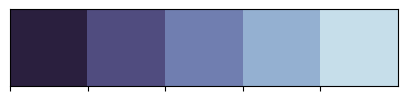

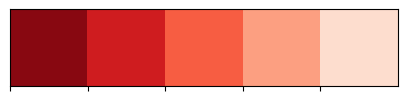

In [28]:
number_of_owns = len(selected)
own_sboxes_index = selected

COLORS_FOR_OWNS = sns.color_palette("ch:s=.25,rot=-.25", n_colors=number_of_owns) [::-1]
#sns.palplot(sns.color_palette("Reds", n_colors=10))[::-3]  # Colores para las S-Boxes propias
COLORS_FOR_CLASICS = sns.color_palette("Reds", n_colors=14)[::-3]
sns.palplot(COLORS_FOR_OWNS)
sns.palplot(COLORS_FOR_CLASICS)

In [29]:
to_proof = ["wage_SB", "wage_WGP"]
specs_clasics = []

for sbox_link in to_proof:
    sbox = load_sbox(f"data/clasics/{sbox_link}.json")
    specs_clasics.append({
        'name': sbox.name,
        'table': sbox.table.tolist(),
        'n_in': sbox.input_size,
        'n_out': sbox.output_size,
        'color': COLORS_FOR_CLASICS[len(specs_clasics) % len(COLORS_FOR_CLASICS)],
        'sbox': sbox
        
    })
    print(f"Procesando S-Box: {sbox.name} ({sbox.input_size}x{sbox.output_size})")

Procesando S-Box: WAGE SB (7x7)
Procesando S-Box: WAGE WGP (7x7)


In [30]:
specs_owns = []

for i in own_sboxes_index:

    with open(f"data/{bits_str}x{bits_str}_sboxes/sbox_{bits_str}_{i}.json", "r", encoding="utf-8") as f:
        data = json.load(f)
    
        table = list(map(lambda x: hex(x), data["best"]))
        n_in  = int(np.log2(len(table)))                    # size of the input
        n_out = int(np.ceil(np.log2(max(data["best"])+1)))  # size of the output
        name = f"Variant #{i}"
            
        sbox = SBox(n_in, n_out, table, name)                    
        specs_owns.append({
            "name": name,              
            "table": data["best"],
            "n_in": n_in,
            "n_out": n_out,
            "color": COLORS_FOR_OWNS[len(specs_owns) % len(COLORS_FOR_OWNS)],
            "sbox":  sbox
        })

print(f"{len(specs_owns)} S-Boxes cargadas desde data.json")


5 S-Boxes cargadas desde data.json


In [31]:

specs = specs_clasics + specs_owns

import matplotlib.colors as mcolors
for spec in specs:
    spec['color'] = mcolors.to_hex(spec['color'])

In [32]:
chart_tv = compare_tv_distance_altair(
    specs,
    r_values=list(range(1,16)),
    log_scale=True,
    detail=True
)
chart_tv

|   r |   Variant #35 |   Variant #37 |   Variant #42 |   Variant #46 |   Variant #48 |     WAGE SB |    WAGE WGP |
|----:|--------------:|--------------:|--------------:|--------------:|--------------:|------------:|------------:|
|   1 |   0.629921    |   0.614173    |   0.622047    |   0.622047    |   0.629921    | 0.685039    | 0.637795    |
|   2 |   0.0710161   |   0.0699761   |   0.0759604   |   0.0711353   |   0.0723541   | 0.0948804   | 0.0709565   |
|   3 |   0.0081651   |   0.00835157  |   0.00846217  |   0.00877786  |   0.00814988  | 0.0147841   | 0.00912208  |
|   4 |   0.000940429 |   0.00100393  |   0.00096448  |   0.00108202  |   0.00101448  | 0.00216682  | 0.00128904  |
|   5 |   0.000117432 |   0.000121424 |   0.000119322 |   0.000118844 |   0.000117579 | 0.00034094  | 0.000173548 |
|   6 |   1.26158e-05 |   1.36392e-05 |   1.38973e-05 |   1.28211e-05 |   1.36857e-05 | 5.93958e-05 | 2.73884e-05 |
|   7 |   1.38844e-06 |   1.46671e-06 |   1.59099e-06 |   1.49698e-06 | 

alt.Chart(...)

In [33]:
chart_mp = compare_max_probability_altair(
    specs,
    r_values=list(range(1,11)),
    log_scale=False,
    detail=True
)
chart_mp

|   r |   Variant #35 |   Variant #37 |   Variant #42 |   Variant #46 |   Variant #48 |    WAGE SB |   WAGE WGP |
|----:|--------------:|--------------:|--------------:|--------------:|--------------:|-----------:|-----------:|
|   1 |    0.046875   |    0.046875   |    0.046875   |    0.046875   |    0.046875   | 0.078125   | 0.046875   |
|   2 |    0.012207   |    0.0134277  |    0.0124512  |    0.0129395  |    0.0129395  | 0.0163574  | 0.0124512  |
|   3 |    0.00834656 |    0.00849152 |    0.00841141 |    0.00839233 |    0.00843048 | 0.00877762 | 0.00872803 |
|   4 |    0.00793314 |    0.00793546 |    0.00792879 |    0.00794137 |    0.00793856 | 0.00799197 | 0.00796837 |
|   5 |    0.00788126 |    0.00788039 |    0.00788051 |    0.00788166 |    0.00788136 | 0.00789678 | 0.0078814  |
|   6 |    0.00787475 |    0.00787487 |    0.00787499 |    0.00787486 |    0.00787495 | 0.00787746 | 0.00787566 |
|   7 |    0.00787411 |    0.0078741  |    0.00787411 |    0.0078741  |    0.00787411 | 

alt.Chart(...)

In [34]:
chart_mix = compare_mixing_times_altair(
    specs,
    epsilons=[10**(-i) for i in range(6,7)],
    max_steps=10000,
    log_scale=True,
)
chart_mix

[1e-06]
WAGE SB with ε=1e-06: 9
WAGE WGP with ε=1e-06: 8
Variant #35 with ε=1e-06: 8
Variant #37 with ε=1e-06: 8
Variant #42 with ε=1e-06: 8
Variant #46 with ε=1e-06: 8
Variant #48 with ε=1e-06: 8


alt.Chart(...)

In [35]:
chart_spec = compare_mixing_times_spectrals_altair(
    specs,
    epsilons=[10**(-i) for i in range(1,10)],
    max_steps=10000,
    log_scale=True,
)
chart_spec

alt.Chart(...)

# Clasicas


=== Métricas de S-Boxes ===
       name  uniformity  max_ddt  fixed_points  non_linearity  avg_sac  max_std_sac
    WAGE SB          10      128             2           42.0 0.475128     0.125477
   WAGE WGP           6      128             2           42.0 0.519133     0.079860
Variant #35           6      128             0           46.0 0.510842     0.072536
Variant #37           6      128             0           46.0 0.501913     0.064694
Variant #42           6      128             0           46.0 0.494898     0.066216
Variant #46           6      128             0           46.0 0.513393     0.081832
Variant #48           6      128             0           48.0 0.505102     0.073627


c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


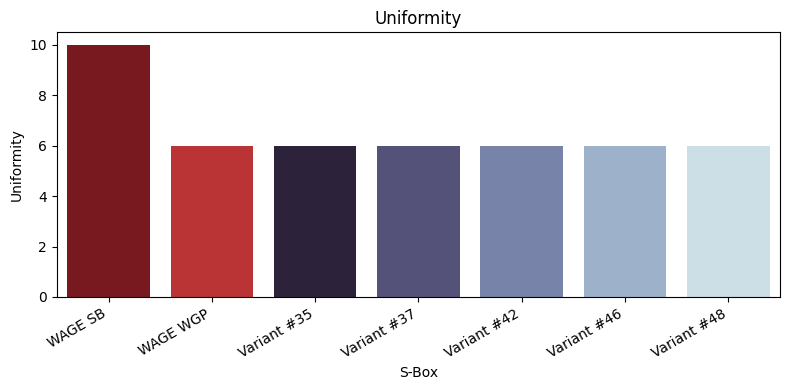

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


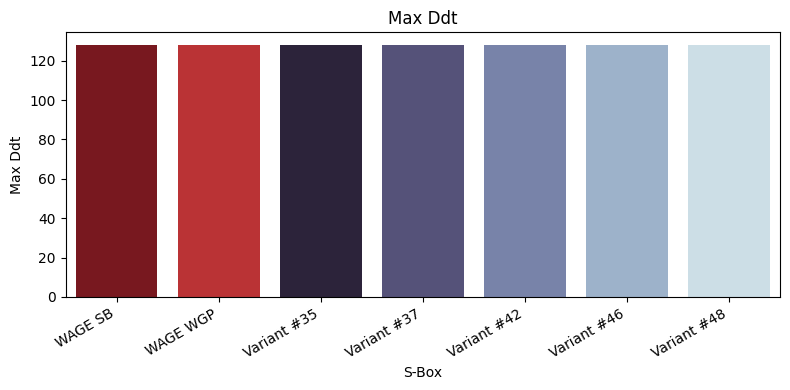

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


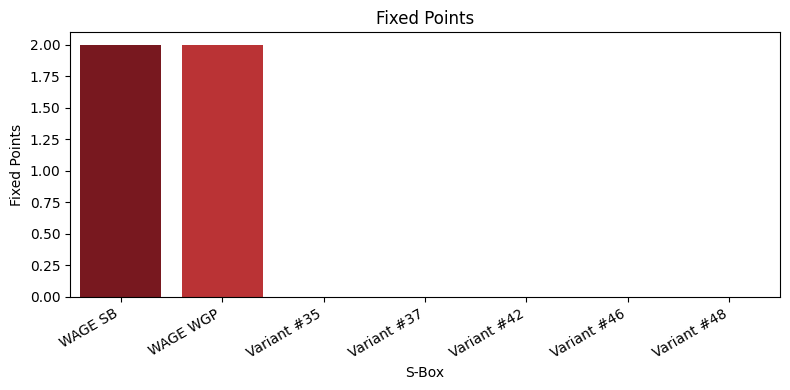

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


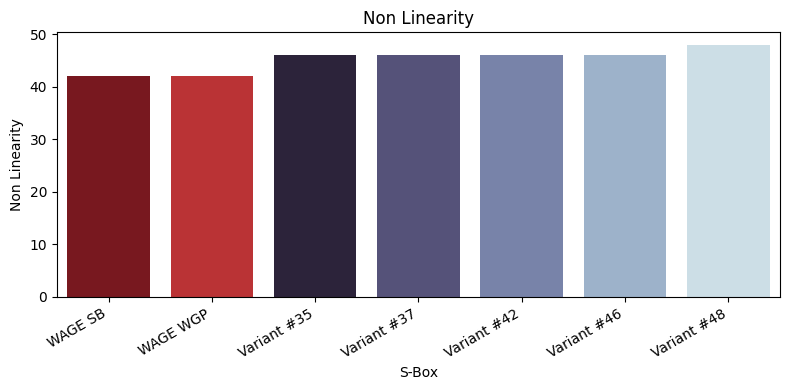

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


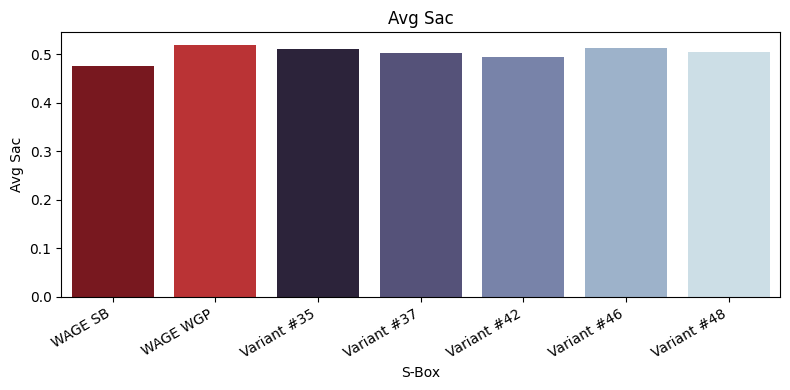

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


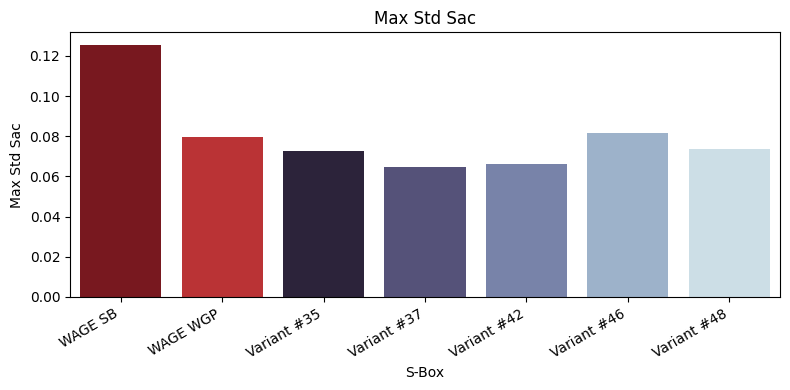

,name,uniformity,max_ddt,fixed_points,non_linearity,avg_sac,max_std_sac
0,WAGE SB,10,128,2,42.0,0.475128,0.125477
1,WAGE WGP,6,128,2,42.0,0.519133,0.079860
2,Variant #35,6,128,0,46.0,0.510842,0.072536
3,Variant #37,6,128,0,46.0,0.501913,0.064694
4,Variant #42,6,128,0,46.0,0.494898,0.066216
5,Variant #46,6,128,0,46.0,0.513393,0.081832
6,Variant #48,6,128,0,48.0,0.505102,0.073627


In [36]:
from evaluation.sbox_metrics_analysis import run_all_metrics

run_all_metrics(specs)

# Ranking

In [37]:
import pandas as pd

# Carga el resumen de métricas generado por run_all_metrics
df = pd.read_csv('sbox_metrics_summary.csv')

# Calcula desviación de avg_sac respecto a 0.5 (ideal SAC = 0.5)
df['sac_error'] = (df['avg_sac'] - 0.5).abs()

# Genera rankings individuales (menor es mejor salvo non_linearity)
df['r_uniformity']    = df['uniformity'].rank(ascending=True)
df['r_max_ddt']       = df['max_ddt'].rank(ascending=True)
df['r_fixed_points']  = df['fixed_points'].rank(ascending=True)
df['r_non_linearity'] = df['non_linearity'].rank(ascending=False)
df['r_sac_error']     = df['sac_error'].rank(ascending=True)
df['r_max_std_sac']   = df['max_std_sac'].rank(ascending=True)

# Suma de rangos como puntaje agregado
rank_cols = ['r_uniformity','r_max_ddt','r_fixed_points',
             'r_non_linearity','r_sac_error','r_max_std_sac']
df['total_rank'] = df[rank_cols].sum(axis=1)

# Ordena y muestra top 5
top5 = df.sort_values('total_rank').reset_index(drop=True)
to_display = top5[['name','total_rank','non_linearity','uniformity',
                   'fixed_points','avg_sac','max_ddt','max_std_sac']].head(5)

print(to_display.to_markdown(index=False))
#import ace_tools as tools; tools.display_dataframe_to_user(name="Top 5 S-Boxes por puntaje agregado", dataframe=to_display)


| name        |   total_rank |   non_linearity |   uniformity |   fixed_points |   avg_sac |   max_ddt |   max_std_sac |
|:------------|-------------:|----------------:|-------------:|---------------:|----------:|----------:|--------------:|
| Variant #37 |         16   |              46 |            6 |              0 |  0.501913 |       128 |     0.0646936 |
| Variant #48 |         17.5 |              48 |            6 |              0 |  0.505102 |       128 |     0.0736269 |
| Variant #42 |         19   |              46 |            6 |              0 |  0.494898 |       128 |     0.0662161 |
| Variant #35 |         21   |              46 |            6 |              0 |  0.510842 |       128 |     0.0725361 |
| Variant #46 |         25   |              46 |            6 |              0 |  0.513393 |       128 |     0.0818317 |
